In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

# Load the Phase 2 processed dataset
DATA_PATH = Path("../data/processed/heart_disease_clean.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

print("\nScikit-learn version:", sklearn.__version__)


Dataset shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Target distribution:
target
0    164
1    139
Name: count, dtype: int64

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Scikit-learn version: 1.9.1


In [2]:

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Feature groups based on the Cleveland dataset
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Separate predictors and binary target
X = df.drop(columns=["target"])
y = df["target"].astype(int)

# Reproducible, stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical: median imputation + standardization
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: most-frequent imputation + one-hot encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Training target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


Training records: 242
Testing records: 61
Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


In [3]:

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=2,
            random_state=42,
            class_weight=None,
            n_jobs=-1
        ))
    ])
}

print("Models defined:")
for model_name in models:
    print("-", model_name)


Models defined:
- Logistic Regression
- Random Forest


In [4]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []
test_results = []
trained_models = {}

for name, model in models.items():
    print(f"\n{'=' * 55}")
    print(f"Model: {name}")
    print("=" * 55)

    # Cross-validation uses training data only
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        cv_row[f"CV {metric} mean"] = values.mean()
        cv_row[f"CV {metric} std"] = values.std()

    cv_results.append(cv_row)

    # Fit the full pipeline on the training set
    model.fit(X_train, y_train)
    trained_models[name] = model

    # Predict the held-out test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
    test_results.append(test_row)

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

# Tabulate cross-validation results
cv_df = pd.DataFrame(cv_results).set_index("Model")
print("\nCROSS-VALIDATION RESULTS")
display(cv_df.round(3))

# Tabulate held-out test results
results_df = pd.DataFrame(test_results).set_index("Model")
print("\nTEST-SET RESULTS")
display(results_df.round(3))



Model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion matrix:
[[28  5]
 [ 2 26]]

Model: Random Forest

Classification report:
              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61

Confusion matrix:
[[27  6]
 [ 2 26]]

CROSS-VALIDATION RESULTS


,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression,0.847,0.010,0.877,0.054,0.783,0.046,0.825,0.007,0.902,0.014
Random Forest,0.814,0.023,0.797,0.027,0.801,0.080,0.796,0.036,0.894,0.033



TEST-SET RESULTS


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.885,0.839,0.929,0.881,0.966
Random Forest,0.869,0.812,0.929,0.867,0.944


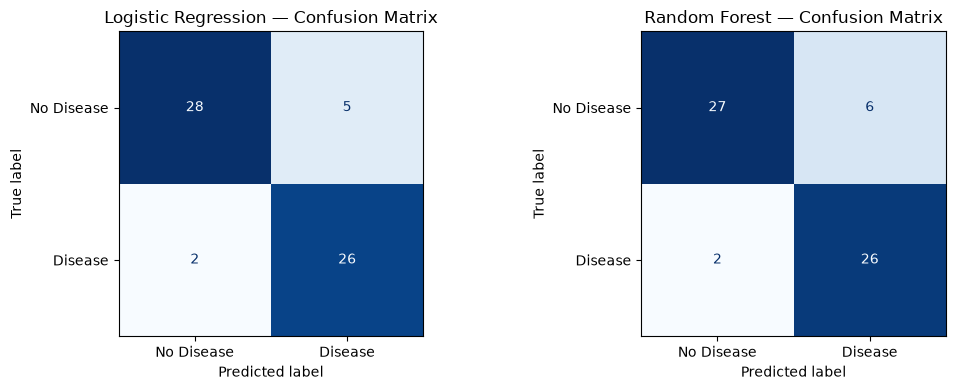

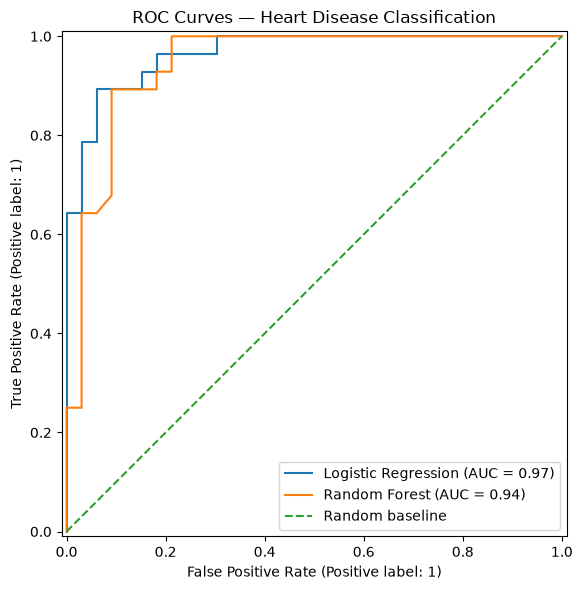

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No Disease", "Disease"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name} — Confusion Matrix")

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(7, 6))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curves — Heart Disease Classification")
ax.legend()
plt.tight_layout()
plt.show()


In [6]:

print("Five-fold cross-validation results:")
display(cv_df.round(3))

print("Held-out test-set comparison:")
display(results_df.round(3))


Five-fold cross-validation results:


,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression,0.847,0.010,0.877,0.054,0.783,0.046,0.825,0.007,0.902,0.014
Random Forest,0.814,0.023,0.797,0.027,0.801,0.080,0.796,0.036,0.894,0.033


Held-out test-set comparison:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.885,0.839,0.929,0.881,0.966
Random Forest,0.869,0.812,0.929,0.867,0.944


In [7]:

from sklearn.model_selection import GridSearchCV

# Use the same reproducible five-fold strategy
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Candidate hyperparameters
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2],
        "classifier__class_weight": [None, "balanced"]
    }
}

best_estimators = {}
tuning_results = []

for name, pipeline in models.items():
    print(f"\nTuning {name}...")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=tuning_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        error_score="raise"
    )

    # Tune using training data only
    search.fit(X_train, y_train)

    best_estimators[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best parameters": search.best_params_
    })

    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_df = pd.DataFrame(tuning_results).set_index("Model")

print("\nTUNING SUMMARY")
display(tuning_df)



Tuning Logistic Regression...
Best CV ROC-AUC: 0.9028
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Tuning Random Forest...
Best CV ROC-AUC: 0.9034
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 400}

TUNING SUMMARY


,Best CV ROC-AUC,Best parameters
Model,,
Logistic Regression,0.902790,"{'classifier__C': 0.1, 'classifier__class_weig..."
Random Forest,0.903415,"{'classifier__class_weight': None, 'classifier..."


In [8]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

tuned_test_results = []

for name, model in best_estimators.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = (
    pd.DataFrame(tuned_test_results)
    .set_index("Model")
)

print("TUNED MODEL TEST RESULTS")
display(tuned_results_df.round(3))

print("\nTuned model classification reports:")
for name, model in best_estimators.items():
    print(f"\n{name}")
    print(classification_report(
        y_test,
        model.predict(X_test),
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))


TUNED MODEL TEST RESULTS


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.885,0.839,0.929,0.881,0.965
Random Forest,0.869,0.812,0.929,0.867,0.948



Tuned model classification reports:

Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61


Random Forest
              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



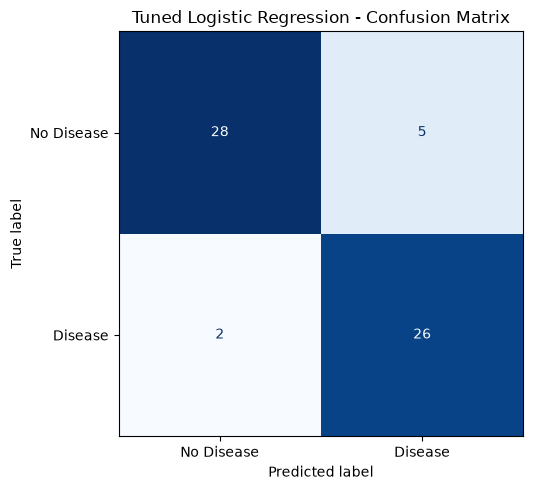

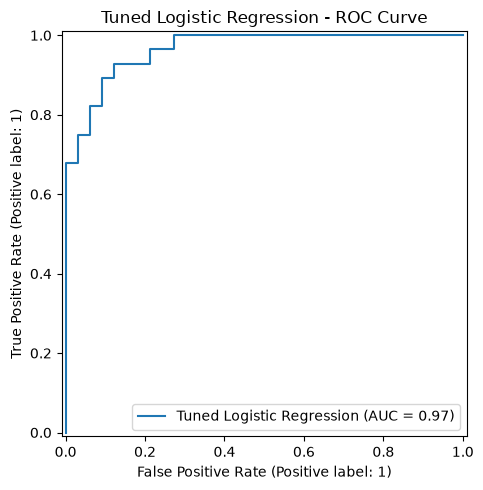

Phase 3 artifacts saved successfully.
Model: d:\Code\MLOPS\heart-disease-mlops\models\heart_disease_pipeline.joblib
Metrics: d:\Code\MLOPS\heart-disease-mlops\report\phase3\metrics.json
Classification report: d:\Code\MLOPS\heart-disease-mlops\report\phase3\classification_report.txt
Plots: d:\Code\MLOPS\heart-disease-mlops\report\phase3

Final test metrics:
{
    "accuracy": 0.8852459016393442,
    "precision": 0.8387096774193549,
    "recall": 0.9285714285714286,
    "f1_score": 0.8813559322033898,
    "roc_auc": 0.9653679653679654
}


In [9]:

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
)

# Locate project root from the notebooks directory
PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "models"
ARTIFACT_DIR = PROJECT_ROOT / "report" / "phase3"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Select the tuned Logistic Regression pipeline
final_model = best_estimators["Logistic Regression"]

# Save the complete preprocessing + model pipeline
model_path = MODEL_DIR / "heart_disease_pipeline.joblib"
joblib.dump(final_model, model_path)

# Collect final evaluation metrics
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "selected_model": "Logistic Regression",
    "selection_basis": (
        "Best overall cross-validation and test-set "
        "performance among the two evaluated classifiers"
    ),
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(
            precision_score(y_test, y_pred, zero_division=0)
        ),
        "recall": float(
            recall_score(y_test, y_pred, zero_division=0)
        ),
        "f1_score": float(
            f1_score(y_test, y_pred, zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(y_test, y_prob))
    },
    "best_parameters": best_estimators[
        "Logistic Regression"
    ].get_params()["classifier"].get_params()
}

# Keep only the key hyperparameters for the report
final_metrics["best_parameters"] = {
    "C": final_metrics["best_parameters"]["C"],
    "class_weight": final_metrics["best_parameters"]["class_weight"],
    "max_iter": final_metrics["best_parameters"]["max_iter"]
}

# Save metrics as JSON
metrics_path = ARTIFACT_DIR / "metrics.json"
with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(final_metrics, file, indent=4)

# Save detailed classification report
report_path = ARTIFACT_DIR / "classification_report.txt"
with open(report_path, "w", encoding="utf-8") as file:
    file.write(classification_report(
        y_test,
        y_pred,
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))

# Save confusion matrix plot
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues",
    ax=ax,
    colorbar=False
)
ax.set_title("Tuned Logistic Regression - Confusion Matrix")
fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Tuned Logistic Regression",
    ax=ax
)
ax.set_title("Tuned Logistic Regression - ROC Curve")
fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "roc_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Phase 3 artifacts saved successfully.")
print("Model:", model_path)
print("Metrics:", metrics_path)
print("Classification report:", report_path)
print("Plots:", ARTIFACT_DIR)
print("\nFinal test metrics:")
print(json.dumps(final_metrics["test_metrics"], indent=4))


In [11]:

loaded_model = joblib.load(model_path)

original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Model reload verification passed.")
print("Test records:", len(X_test))
print(
    "Predictions identical after reload:",
    np.array_equal(original_predictions, loaded_predictions)
)


Model reload verification passed.
Test records: 61
Predictions identical after reload: True


In [12]:

import mlflow

print("MLflow version:", mlflow.__version__)


MLflow version: 3.16.1


In [16]:

from pathlib import Path

import mlflow

# Resolve the project root safely
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

# Create directories
TRACKING_DB = PROJECT_ROOT / "mlflow.db"
ARTIFACT_DIR = PROJECT_ROOT / "report" / "phase4"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Configure SQLite tracking backend
tracking_uri = f"sqlite:///{TRACKING_DB.as_posix()}"
mlflow.set_tracking_uri(tracking_uri)

# Create or reuse the experiment
experiment_name = "Heart-Disease-Classification"
experiment = mlflow.set_experiment(experiment_name)

print("MLflow version:", mlflow.__version__)
print("Project root:", PROJECT_ROOT)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Database:", TRACKING_DB)
print("Configuration successful!")


2026/10/11 12:45:36 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 12:45:36 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 12:45:38 INFO mlflow.tracking.fluent: Experiment with name 'Heart-Disease-Classification' does not exist. Creating a new experiment.


MLflow version: 3.16.1
Project root: d:\Code\MLOPS\heart-disease-mlops
Tracking URI: sqlite:///d:/Code/MLOPS/heart-disease-mlops/mlflow.db
Experiment name: Heart-Disease-Classification
Experiment ID: 1
Database: d:\Code\MLOPS\heart-disease-mlops\mlflow.db
Configuration successful!


In [17]:

with mlflow.start_run(run_name="tracking_setup_test"):
    mlflow.log_param("test_parameter", "phase4")
    mlflow.log_metric("test_metric", 1.0)

print("SQLite tracking test passed.")


SQLite tracking test passed.


In [20]:

import json
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# --------------------------------------------------
# 1. Configure MLflow with the SQLite database
# --------------------------------------------------
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

TRACKING_DB = PROJECT_ROOT / "mlflow.db"
ARTIFACT_DIR = PROJECT_ROOT / "report" / "phase4"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(
    f"sqlite:///{TRACKING_DB.as_posix()}"
)

mlflow.set_experiment("Heart-Disease-Classification")

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

# --------------------------------------------------
# 2. Verify Phase 3 variables
# --------------------------------------------------
required_models = {"Logistic Regression", "Random Forest"}

if not required_models.issubset(best_estimators.keys()):
    raise ValueError(
        "best_estimators must contain Logistic Regression "
        "and Random Forest. Rerun Phase 3 tuning first."
    )

if not X_test.index.equals(y_test.index):
    raise ValueError("X_test and y_test indices do not match.")

mlflow_results = []

# --------------------------------------------------
# 3. Log both tuned model experiments
# --------------------------------------------------
for name, model in best_estimators.items():

    print(f"\n{'=' * 60}")
    print("Logging model:", name)
    print("=" * 60)

    # Predictions from the already-fitted model
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Test metrics
    test_metrics = {
        "test_accuracy": float(
            accuracy_score(y_test, y_pred)
        ),
        "test_precision": float(
            precision_score(
                y_test, y_pred, zero_division=0
            )
        ),
        "test_recall": float(
            recall_score(
                y_test, y_pred, zero_division=0
            )
        ),
        "test_f1": float(
            f1_score(
                y_test, y_pred, zero_division=0
            )
        ),
        "test_roc_auc": float(
            roc_auc_score(y_test, y_prob)
        )
    }

    safe_name = name.lower().replace(" ", "_")
    run_artifact_dir = ARTIFACT_DIR / safe_name
    run_artifact_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------
    # 4. Create evaluation artifacts
    # --------------------------------------------------

    # Classification report
    report_text = classification_report(
        y_test,
        y_pred,
        target_names=["No Disease", "Disease"],
        zero_division=0
    )

    report_path = (
        run_artifact_dir / "classification_report.txt"
    )
    report_path.write_text(
        report_text,
        encoding="utf-8"
    )

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Disease", "Disease"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{name} - Confusion Matrix")
    fig.tight_layout()

    cm_path = run_artifact_dir / "confusion_matrix.png"
    fig.savefig(
        cm_path,
        dpi=180,
        bbox_inches="tight"
    )
    plt.close(fig)

    # ROC curve
    fig, ax = plt.subplots(figsize=(6, 5))

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=ax
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random baseline"
    )

    ax.set_title(f"{name} - ROC Curve")
    ax.legend()
    fig.tight_layout()

    roc_path = run_artifact_dir / "roc_curve.png"
    fig.savefig(
        roc_path,
        dpi=180,
        bbox_inches="tight"
    )
    plt.close(fig)

    # Save the metrics locally as JSON too
    metrics_path = run_artifact_dir / "metrics.json"
    metrics_path.write_text(
        json.dumps(test_metrics, indent=4),
        encoding="utf-8"
    )

    # --------------------------------------------------
    # 5. Create MLflow run and log parameters/metrics
    # --------------------------------------------------
    with mlflow.start_run(run_name=name) as active_run:

        mlflow.set_tag("project", "heart-disease-mlops")
        mlflow.set_tag("model_family", name)
        mlflow.set_tag("stage", "phase4-experiment-tracking")

        # Common experiment parameters
        mlflow.log_param("model_name", name)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("test_records", len(X_test))
        mlflow.log_param("selection_metric", "roc_auc")

        # Tuned classifier parameters
        classifier_params = (
            model.named_steps["classifier"].get_params()
        )

        for key, value in classifier_params.items():
            if isinstance(
                value, (str, int, float, bool)
            ) or value is None:
                mlflow.log_param(
                    f"classifier_{key}",
                    str(value) if value is None else value
                )

        # Cross-validation metrics from Phase 3
        cv_row = cv_df.loc[name]

        for metric in [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ]:
            mlflow.log_metric(
                f"cv_{metric}_mean",
                float(cv_row[f"CV {metric} mean"])
            )

            mlflow.log_metric(
                f"cv_{metric}_std",
                float(cv_row[f"CV {metric} std"])
            )

        # Held-out test metrics
        mlflow.log_metrics(test_metrics)

        # Log evaluation files
        mlflow.log_artifact(
            str(report_path),
            artifact_path="evaluation"
        )

        mlflow.log_artifact(
            str(cm_path),
            artifact_path="evaluation"
        )

        mlflow.log_artifact(
            str(roc_path),
            artifact_path="evaluation"
        )

        mlflow.log_artifact(
            str(metrics_path),
            artifact_path="evaluation"
        )

        # --------------------------------------------------
        # 6. Log fitted pipeline using Pickle serialization
        # --------------------------------------------------
        mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            serialization_format="pickle",
            input_example=X_train.head(2)
        )

        # Store run information for verification
        mlflow_results.append({
            "Model": name,
            "Run ID": active_run.info.run_id,
            **test_metrics
        })

    print("Run completed:", active_run.info.run_id)
    print("Test ROC-AUC:", round(test_metrics["test_roc_auc"], 4))

# --------------------------------------------------
# 7. Display experiment summary
# --------------------------------------------------
print("\nMLflow logging completed successfully.")

mlflow_results_df = (
    pd.DataFrame(mlflow_results)
    .set_index("Model")
)

display(mlflow_results_df.round(3))

print("\nLocal evaluation artifacts:", ARTIFACT_DIR)
print("SQLite tracking database:", TRACKING_DB)


MLflow version: 3.16.1
Tracking URI: sqlite:///d:/Code/MLOPS/heart-disease-mlops/mlflow.db

Logging model: Logistic Regression


2026/10/11 12:49:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
d:\Code\MLOPS\heart-disease-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing valu

Run completed: 9c4f1f99bf5d4897a4639ebcabd7e225
Test ROC-AUC: 0.9654

Logging model: Random Forest


2026/10/11 12:50:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
d:\Code\MLOPS\heart-disease-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing valu

Run completed: bdaa1ff1f1e1481d847942e84c6e1dc5
Test ROC-AUC: 0.9481

MLflow logging completed successfully.


,Run ID,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
Model,,,,,,
Logistic Regression,9c4f1f99bf5d4897a4639ebcabd7e225,0.885,0.839,0.929,0.881,0.965
Random Forest,bdaa1ff1f1e1481d847942e84c6e1dc5,0.869,0.812,0.929,0.867,0.948



Local evaluation artifacts: d:\Code\MLOPS\heart-disease-mlops\report\phase4
SQLite tracking database: d:\Code\MLOPS\heart-disease-mlops\mlflow.db


In [21]:

from pathlib import Path

import mlflow
import pandas as pd

# 1. Connect to the same SQLite database used in Step 3
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

TRACKING_DB = PROJECT_ROOT / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{TRACKING_DB.as_posix()}"
)

# 2. Find the experiment
experiment_name = "Heart-Disease-Classification"

experiment = mlflow.get_experiment_by_name(
    experiment_name
)

if experiment is None:
    raise ValueError(
        f"Experiment '{experiment_name}' not found. "
        "Run Step 2 and Step 3 first."
    )

print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())

# 3. Retrieve all runs
runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

if runs_df.empty:
    raise ValueError(
        "No MLflow runs found. Check whether Step 3 completed."
    )

# 4. Display useful metrics
display_columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.cv_accuracy_mean",
    "metrics.cv_precision_mean",
    "metrics.cv_recall_mean",
    "metrics.cv_f1_mean",
    "metrics.cv_roc_auc_mean",
    "metrics.test_accuracy",
    "metrics.test_precision",
    "metrics.test_recall",
    "metrics.test_f1",
    "metrics.test_roc_auc",
    "run_id"
]

available_columns = [
    col for col in display_columns
    if col in runs_df.columns
]

print("\nMLflow experiment runs:")
display(runs_df[available_columns].round(3))

# 5. Verify that both model runs completed
completed_runs = runs_df[
    runs_df["status"] == "FINISHED"
]

run_names = set(
    completed_runs["tags.mlflow.runName"].dropna()
)

required_models = {
    "Logistic Regression",
    "Random Forest"
}

missing_models = required_models - run_names

if missing_models:
    raise AssertionError(
        f"Missing completed model runs: {missing_models}"
    )

print("\nVerification passed!")
print("Completed runs:", len(completed_runs))
print("Both Logistic Regression and Random Forest are recorded.")


Experiment: Heart-Disease-Classification
Experiment ID: 1
Tracking URI: sqlite:///d:/Code/MLOPS/heart-disease-mlops/mlflow.db

MLflow experiment runs:


,tags.mlflow.runName,status,metrics.cv_accuracy_mean,metrics.cv_precision_mean,metrics.cv_recall_mean,metrics.cv_f1_mean,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc,run_id
0,Random Forest,FINISHED,0.814,0.797,0.801,0.796,0.894,0.869,0.812,0.929,0.867,0.948,bdaa1ff1f1e1481d847942e84c6e1dc5
1,Logistic Regression,FINISHED,0.847,0.877,0.783,0.825,0.902,0.885,0.839,0.929,0.881,0.965,9c4f1f99bf5d4897a4639ebcabd7e225
2,Logistic Regression,FAILED,0.847,0.877,0.783,0.825,0.902,0.885,0.839,0.929,0.881,0.965,d1a85782994a452e91e8a32cf35a0884
3,Logistic Regression,FAILED,0.847,0.877,0.783,0.825,0.902,0.885,0.839,0.929,0.881,0.965,cc61af07dae0473abcd96ef77ecc83c3
4,tracking_setup_test,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76ba34860bc4419a80e23a783167cef6



Verification passed!
Completed runs: 3
Both Logistic Regression and Random Forest are recorded.
